# 11.15日学习笔记
## 1.mlp_scratch
### 1.1基础代码

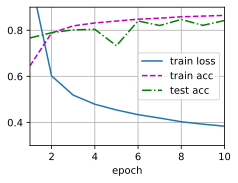

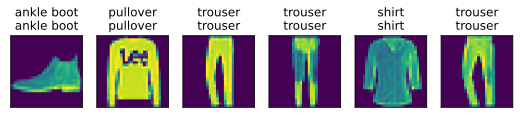

In [5]:
# 导入基本的库
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
# 初始化模型参数
num_inputs, num_outputs, num_hiddens = 784, 10, 256
W1 = nn.Parameter(torch.randn(num_inputs, num_hiddens, requires_grad=True)*0.01)
b1 = nn.Parameter(torch.zeros(num_hiddens, requires_grad=True))
W2 = nn.Parameter(torch.randn(num_hiddens, num_outputs, requires_grad=True)*0.01)
b2 = nn.Parameter(torch.zeros(num_outputs, requires_grad=True))
params = [W1, b1, W2, b2]
# 激活函数
def relu(X):
    a=torch.zeros_like(X)
    return torch.max(X,a)
# 模型
def net(X):
    X=X.reshape((-1,num_inputs))
    H=relu(X@W1+b1)
    return(H@W2+b2)
# 损失函数
loss = nn.CrossEntropyLoss(reduction='none')
# 训练
num_epochs, lr=10,0.1
updater = torch.optim.SGD(params, lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, updater)
# 评估
d2l.predict_ch3(net, test_iter)

### 1.2 exercise
1.在所有其他参数保持不变的情况下，更改超参数num_hiddes的值，并查看此超参数的变化对结果有何影响。确定此超参数的最佳值

answer:g




正在训练 num_hiddens = 32
训练损失: 0.6948
训练准确率: 0.7519
测试准确率: 0.6926

正在训练 num_hiddens = 64
训练损失: 0.6998
训练准确率: 0.7471
测试准确率: 0.7268

正在训练 num_hiddens = 128
训练损失: 0.6820
训练准确率: 0.7852
测试准确率: 0.7631

正在训练 num_hiddens = 256
训练损失: 0.7415
训练准确率: 0.7997
测试准确率: 0.7629

正在训练 num_hiddens = 512
训练损失: 0.8864
训练准确率: 0.8172
测试准确率: 0.7897

实验结果汇总
隐藏层神经元 | 训练损失 | 训练准确率 | 测试准确率
          32 |   0.6948 |     0.7519 |     0.6926
          64 |   0.6998 |     0.7471 |     0.7268
         128 |   0.6820 |     0.7852 |     0.7631
         256 |   0.7415 |     0.7997 |     0.7629
         512 |   0.8864 |     0.8172 |     0.7897


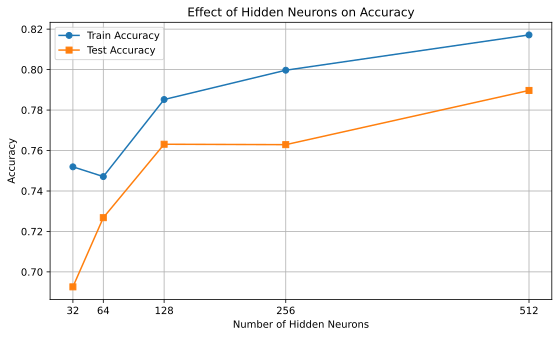


最佳隐藏层神经元数量: 512
最高测试准确率: 0.7897


In [12]:

import torch
from torch import nn
from d2l import torch as d2l
import matplotlib.pyplot as plt

# 1. 基本参数
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

num_inputs, num_outputs = 784, 10
num_epochs, lr = 10, 0.1

# 测试不同的隐藏层神经元数量
hidden_sizes = [32, 64, 128, 256, 512]

# 2. 定义激活函数
def relu(X):
    a = torch.zeros_like(X)
    return torch.max(X, a)

# 3. 保存实验结果
results = []

# 4. 依次训练不同隐藏层大小的模型
for num_hiddens in hidden_sizes:

    print(f"\n正在训练 num_hiddens = {num_hiddens}")

    # 初始化参数
    torch.manual_seed(42)

    W1 = nn.Parameter(torch.randn(
        num_inputs, num_hiddens, requires_grad=True))
    b1 = nn.Parameter(torch.zeros(
        num_hiddens, requires_grad=True))
    W2 = nn.Parameter(torch.randn(
        num_hiddens, num_outputs, requires_grad=True))
    b2 = nn.Parameter(torch.zeros(
        num_outputs, requires_grad=True))

    params = [W1, b1, W2, b2]

    # 定义网络
    def net(X):
        X = X.reshape((-1, num_inputs))
        H = relu(X @ W1 + b1)
        return H @ W2 + b2

    # 损失函数和优化器
    loss = nn.CrossEntropyLoss(reduction='none')
    updater = torch.optim.SGD(params, lr=lr)

    # 固定数据打乱的随机种子
    torch.manual_seed(2026)

    # 训练模型
    for epoch in range(num_epochs):
        train_loss, train_acc = d2l.train_epoch_ch3(
            net, train_iter, loss, updater)

        test_acc = d2l.evaluate_accuracy(net, test_iter)

    # 保存最终结果
    results.append([
        num_hiddens,
        train_loss,
        train_acc,
        test_acc
    ])

    print(f"训练损失: {train_loss:.4f}")
    print(f"训练准确率: {train_acc:.4f}")
    print(f"测试准确率: {test_acc:.4f}")


# 5. 输出实验结果
print("\n实验结果汇总")
print("隐藏层神经元 | 训练损失 | 训练准确率 | 测试准确率")

for r in results:
    print(f"{r[0]:12d} | {r[1]:8.4f} | "
          f"{r[2]:10.4f} | {r[3]:10.4f}")


# 6. 绘制准确率对比图
hidden_sizes = [r[0] for r in results]
train_accs = [r[2] for r in results]
test_accs = [r[3] for r in results]

plt.figure(figsize=(9, 5))

plt.plot(hidden_sizes, train_accs,
         marker='o', label='Train Accuracy')

plt.plot(hidden_sizes, test_accs,
         marker='s', label='Test Accuracy')

plt.xlabel('Number of Hidden Neurons')
plt.ylabel('Accuracy')
plt.title('Effect of Hidden Neurons on Accuracy')

plt.xticks(hidden_sizes)
plt.grid(True)
plt.legend()
plt.show()


# 7. 找到测试准确率最高的模型
best = max(results, key=lambda x: x[3])

print(f"\n最佳隐藏层神经元数量: {best[0]}")
print(f"最高测试准确率: {best[3]:.4f}")


2.尝试添加更多的隐藏层，并查看它对结果有何影响。

answer:

添加了一层，感觉测试集的成功率开始更稳定地上升，少了很多大回撤

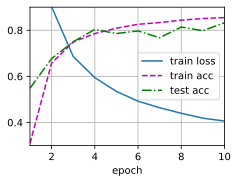

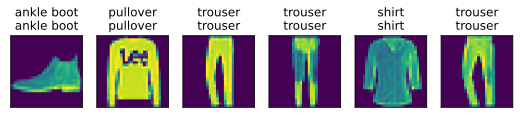

In [10]:
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
num_inputs, num_outputs, num_hiddens_1, num_hiddens_2 = 784, 10, 256, 128
W1 = nn.Parameter(torch.randn(num_inputs, num_hiddens_1, requires_grad=True)*0.01)
b1 = nn.Parameter(torch.zeros(num_hiddens_1, requires_grad=True))
W2 = nn.Parameter(torch.randn(num_hiddens_1, num_hiddens_2, requires_grad=True)*0.01)
b2 = nn.Parameter(torch.zeros(num_hiddens_2, requires_grad=True))
W3 = nn.Parameter(torch.randn(num_hiddens_2, num_outputs, requires_grad=True)*0.01)
b3 = nn.Parameter(torch.zeros(num_outputs, requires_grad=True))
params = [W1, b1, W2, b2, W3, b3]
def relu(X):
    a=torch.zeros_like(X)
    return torch.max(X,a)
def net(X):
    X=X.reshape((-1,num_inputs))
    H_1=relu(X@W1+b1)
    H_2=relu(H_1@W2+b2)
    return(H_2@W3+b3)
loss = nn.CrossEntropyLoss(reduction='none')
num_epochs, lr=10,0.1
updater = torch.optim.SGD(params, lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, updater)
d2l.predict_ch3(net, test_iter)

3.改变学习速率会如何影响结果？保持模型架构和其他超参数不变，学习率设置为多少会带来最好的结果？

answer:



In [13]:
import torch
from torch import nn
from d2l import torch as d2l

batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

num_inputs, num_hiddens, num_outputs = 784, 256, 10
num_epochs = 10
learning_rates = [0.01, 0.03, 0.1, 0.3, 1.0]

loss = nn.CrossEntropyLoss(reduction='none')
results = []

for lr in learning_rates:
    torch.manual_seed(42)

    W1 = nn.Parameter(torch.randn(num_inputs, num_hiddens) * 0.01)
    b1 = nn.Parameter(torch.zeros(num_hiddens))
    W2 = nn.Parameter(torch.randn(num_hiddens, num_outputs) * 0.01)
    b2 = nn.Parameter(torch.zeros(num_outputs))

    def net(X):
        X = X.reshape(-1, num_inputs)
        H = torch.relu(X @ W1 + b1)
        return H @ W2 + b2

    updater = torch.optim.SGD([W1, b1, W2, b2], lr=lr)

    # 手动循环，避免 train_ch3 的末尾断言中断学习率比较
    for epoch in range(num_epochs):
        train_loss, train_acc = d2l.train_epoch_ch3(
            net, train_iter, loss, updater
        )

    test_acc = d2l.evaluate_accuracy(net, test_iter)
    results.append((lr, test_acc))

    print(
        f"学习率={lr:<5} "
        f"训练损失={train_loss:.4f} "
        f"训练准确率={train_acc:.4f} "
        f"测试准确率={test_acc:.4f}"
    )

best_lr, best_acc = max(results, key=lambda x: x[1])
print(f"\n本次实验最佳学习率：{best_lr}，测试准确率：{best_acc:.4f}")

学习率=0.01  训练损失=0.6482 训练准确率=0.7755 测试准确率=0.7689
学习率=0.03  训练损失=0.4779 训练准确率=0.8364 测试准确率=0.8239
学习率=0.1   训练损失=0.3821 训练准确率=0.8665 测试准确率=0.8443
学习率=0.3   训练损失=0.3145 训练准确率=0.8853 测试准确率=0.8568
学习率=1.0   训练损失=1.9238 训练准确率=0.2557 测试准确率=0.2647

本次实验最佳学习率：0.3，测试准确率：0.8568


4.通过对所有超参数进行联合优化，可以得到的最佳结果是什么？

answer:

这个要做超级多实验，从略

5.描述为什么涉及多个超参数更具挑战性

answer:

当我们想要最优化一个n个超参数的模型，假设一个超参数有10个带选项，就有
$$10^{n}$$组实验，太过复杂

6.如果想要构建多个超参数的搜索方法，请想出一个聪明的策略

answer:

先给每个超参数设定合理的搜索范围  
然后随机选择若干组超参数的组合  
淘汰掉明显差的几个 
在表现较好的几组附近继续做实验


## 2.mlp_concise
### 2.1 简洁实现

In [ ]:
import torch
from torch import nn
from d2l import torch as d2l
net = nn.Sequential(nn.Flatten(),
                    nn.Linear(784, 256),
                    nn.ReLU(),
                    nn.Linear(256, 10))

def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights);
batch_size, lr, num_epochs = 256, 0.1, 10
loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=lr)
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

## 2.2exercise
1.尝试添加不同数量的隐藏层
2.尝试不同的激活函数
3.尝试不同的方案初始化权重

In [ ]:
import torch
from torch import nn
from d2l import torch as d2l
import matplotlib.pyplot as plt

# 超参数
batch_size = 256
lr = 0.1
num_epochs = 10

# 损失函数
loss = nn.CrossEntropyLoss(reduction='none')

# 加载数据
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

# 设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)
def build_net(activation):
    net = nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 256),
        activation(),
        nn.Linear(256, 10)
    )
    return net
def init_weights(net, method):
    for m in net.modules():
        if isinstance(m, nn.Linear):

            if method == 'normal':
                nn.init.normal_(m.weight, mean=0, std=0.01)

            elif method == 'xavier':
                nn.init.xavier_normal_(m.weight)

            elif method == 'kaiming':
                nn.init.kaiming_normal_(
                    m.weight,
                    mode='fan_in',
                    nonlinearity='relu'
                )

            elif method == 'zero':
                nn.init.zeros_(m.weight)

            elif method == 'default':
                pass

            # 所有实验统一将偏置初始化为0
            if m.bias is not None:
                nn.init.zeros_(m.bias)
def train_model(activation, init_method, seed=42):

    torch.manual_seed(seed)

    net = build_net(activation).to(device)

    # 初始化权重
    init_weights(net, init_method)

    # 优化器
    trainer = torch.optim.SGD(net.parameters(), lr=lr)

    # 保存每一轮的实验结果
    history = {
        'train_loss': [],
        'test_loss': [],
        'train_acc': [],
        'test_acc': []
    }

    for epoch in range(num_epochs):

        net.train()

        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        # 保证不同实验的数据打乱顺序尽量一致
        torch.manual_seed(seed + epoch)

        for X, y in train_iter:

            X, y = X.to(device), y.to(device)

            # 前向传播
            y_hat = net(X)

            # 计算损失
            l = loss(y_hat, y)

            # 反向传播
            trainer.zero_grad()
            l.mean().backward()

            # 更新参数
            trainer.step()

            # 统计训练指标
            train_loss_sum += l.sum().item()
            train_correct += (y_hat.argmax(dim=1) == y).sum().item()
            train_total += y.numel()

        # 训练集指标
        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total

        # 测试集评估
        net.eval()

        test_loss_sum = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():

            for X, y in test_iter:

                X, y = X.to(device), y.to(device)

                y_hat = net(X)
                l = loss(y_hat, y)

                test_loss_sum += l.sum().item()
                test_correct += (y_hat.argmax(dim=1) == y).sum().item()
                test_total += y.numel()

        test_loss = test_loss_sum / test_total
        test_acc = test_correct / test_total

        # 保存数据
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)

        print(
            f'Epoch {epoch+1:02d}/{num_epochs} | '
            f'Train Loss: {train_loss:.4f} | '
            f'Test Loss: {test_loss:.4f} | '
            f'Train Acc: {train_acc:.4f} | '
            f'Test Acc: {test_acc:.4f}'
        )

    return net, history
activation_configs = {
    'ReLU': nn.ReLU,
    'Sigmoid': nn.Sigmoid,
    'Tanh': nn.Tanh
}

activation_results = {}

for name, activation in activation_configs.items():

    print(f'\n========== {name} ==========')

    net, history = train_model(
        activation=activation,
        init_method='normal'
    )

    activation_results[name] = history
def plot_results(results, title, save_path=None):

    epochs = range(1, num_epochs + 1)

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))

    metrics = [
        ('train_loss', 'Training Loss'),
        ('test_loss', 'Test Loss'),
        ('train_acc', 'Training Accuracy'),
        ('test_acc', 'Test Accuracy')
    ]

    for ax, (metric, metric_title) in zip(axes.flat, metrics):

        for name, history in results.items():

            ax.plot(
                epochs,
                history[metric],
                marker='o',
                label=name
            )

        ax.set_title(metric_title)
        ax.set_xlabel('Epoch')
        ax.set_xticks(list(epochs))
        ax.grid(True, alpha=0.3)
        ax.legend()

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches='tight')

    plt.show()

cpu

========== ReLU ==========
Epoch 01/10 | Train Loss: 1.0401 | Test Loss: 0.7138 | Train Acc: 0.6455 | Test Acc: 0.7388
Epoch 02/10 | Train Loss: 0.6032 | Test Loss: 0.6695 | Train Acc: 0.7872 | Test Acc: 0.7642
Epoch 03/10 | Train Loss: 0.5221 | Test Loss: 0.5399 | Train Acc: 0.8163 | Test Acc: 0.8087
Epoch 04/10 | Train Loss: 0.4811 | Test Loss: 0.4962 | Train Acc: 0.8312 | Test Acc: 0.8243
Epoch 05/10 | Train Loss: 0.4533 | Test Loss: 0.4771 | Train Acc: 0.8408 | Test Acc: 0.8306
Epoch 06/10 | Train Loss: 0.4315 | Test Loss: 0.4580 | Train Acc: 0.8484 | Test Acc: 0.8398
Epoch 07/10 | Train Loss: 0.4190 | Test Loss: 0.4403 | Train Acc: 0.8526 | Test Acc: 0.8433
Epoch 08/10 | Train Loss: 0.4067 | Test Loss: 0.4306 | Train Acc: 0.8557 | Test Acc: 0.8494
Epoch 09/10 | Train Loss: 0.3944 | Test Loss: 0.4256 | Train Acc: 0.8601 | Test Acc: 0.8490
Epoch 10/10 | Train Loss: 0.3825 | Test Loss: 0.4090 | Train Acc: 0.8635 | Test Acc: 0.8536

========== Sigmoid ==========
Epoch 01/10 | Tra